# 04 — Neural Network Foundations

## Terms & Definitions
- **Linear layer (fully-connected layer)**: computes `y = xW^T + b` — a learned linear transformation of its input.
- **Activation function**: a nonlinear function applied elementwise (e.g. ReLU, GELU) — without these, stacking linear layers would collapse into a single linear layer, no matter how many you stack.
- **Layer normalization (LayerNorm)**: rescales each example's features to have mean 0 and variance 1, then applies a learned scale/shift — stabilizes training in deep networks.
- **Residual connection (skip connection)**: adding a layer's input directly to its output (`x + f(x)`), so gradients have a direct path backward through the network.
- **Softmax**: converts a vector of raw scores ("logits") into a probability distribution that sums to 1.
- **Cross-entropy loss**: the standard loss for classification (including next-token prediction) — measures how far a predicted probability distribution is from the true answer.

## Why This Notebook
Notebook 06 assembles a full Transformer block out of exactly these five pieces. Understanding each in isolation first makes the assembled block much less mysterious.

## The Math (light)

**Linear layer**: $y = xW^T + b$, where $W$ and $b$ are learned parameters.

**GELU activation** (used in GPT-style models, smoother than ReLU):
$$\text{GELU}(x) \approx 0.5x\left(1 + \tanh\left[\sqrt{2/\pi}(x + 0.044715x^3)\right]\right)$$
You don't need to memorize this formula — the point is just that it's a smooth, nonlinear S-shaped curve, and PyTorch computes it for you via `nn.GELU()`.

**LayerNorm**: for each example, $\hat{x} = \dfrac{x - \mu}{\sqrt{\sigma^2 + \epsilon}}$, then $y = \gamma \hat{x} + \beta$ ($\gamma, \beta$ learned).

**Softmax**: $\text{softmax}(z)_i = \dfrac{e^{z_i}}{\sum_j e^{z_j}}$ — turns arbitrary real numbers into positive numbers that sum to 1 (a valid probability distribution).

**Cross-entropy loss**: $L = -\log(p_{\text{correct}})$ — just the negative log-probability the model assigned to the correct answer. If the model puts high probability on the right token, loss is low; if it puts low probability there, loss is high (and grows without bound as $p \to 0$).


In [3]:
import sys
sys.path.insert(0, "..")

import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(0)


## Linear Layers


In [4]:
linear = nn.Linear(in_features=4, out_features=2)
x = torch.randn(3, 4)  # batch of 3 examples, 4 features each
y = linear(x)
print("input shape: ", x.shape)
print("output shape:", y.shape)
print("weight shape:", linear.weight.shape, " bias shape:", linear.bias.shape)


input shape:  torch.Size([3, 4])
output shape: torch.Size([3, 2])
weight shape: torch.Size([2, 4])  bias shape: torch.Size([2])


## Activations: Why Nonlinearity Matters

If you stack two linear layers with nothing in between, the result is *still just one linear function* — no extra representational power. An activation function breaks that: it's what lets a stack of layers represent curves, not just straight lines.


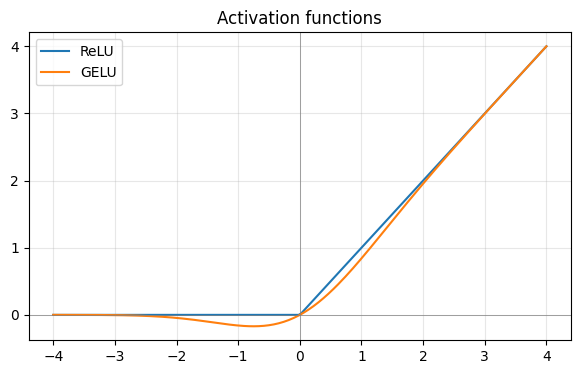

In [5]:
x = torch.linspace(-4, 4, 200)
relu = F.relu(x)
gelu = F.gelu(x)

plt.figure(figsize=(7, 4))
plt.plot(x, relu, label="ReLU")
plt.plot(x, gelu, label="GELU")
plt.axhline(0, color="gray", linewidth=0.5)
plt.axvline(0, color="gray", linewidth=0.5)
plt.legend()
plt.title("Activation functions")
plt.grid(alpha=0.3)
plt.show()


In [6]:
# Proof that stacking linear layers without an activation is pointless:
lin1 = nn.Linear(4, 4, bias=False)
lin2 = nn.Linear(4, 4, bias=False)

combined_weight = lin2.weight @ lin1.weight   # the two linear layers "collapse" into one
single_equivalent = nn.Linear(4, 4, bias=False)
single_equivalent.weight.data = combined_weight

x = torch.randn(1, 4)
out_stacked = lin2(lin1(x))
out_single  = single_equivalent(x)
print("stacked-layers output:", out_stacked)
print("single-layer output: ", out_single)
print("identical (up to floating point):", torch.allclose(out_stacked, out_single, atol=1e-6))


stacked-layers output: tensor([[ 0.0852, -0.3950,  0.1280, -0.0113]], grad_fn=<MmBackward0>)
single-layer output:  tensor([[ 0.0852, -0.3950,  0.1280, -0.0113]], grad_fn=<MmBackward0>)
identical (up to floating point): True


## LayerNorm

Deep networks (many stacked layers) are prone to activations growing too large or too small as they pass through layer after layer. LayerNorm re-centers and re-scales each example's features before the next layer sees them, which empirically makes deep Transformers much easier to train.


In [7]:
ln = nn.LayerNorm(4)
x = torch.tensor([[1.0, 100.0, -50.0, 3.0]])
print("before LayerNorm:", x)
print("after LayerNorm: ", ln(x))
print("mean after:", ln(x).mean().item(), " std after:", ln(x).std(unbiased=False).item())


before LayerNorm: tensor([[  1., 100., -50.,   3.]])
after LayerNorm:  tensor([[-0.2303,  1.5939, -1.1701, -0.1935]],
       grad_fn=<NativeLayerNormBackward0>)
mean after: 1.4901161193847656e-08  std after: 1.0


## Residual (Skip) Connections

Instead of `x = layer(x)`, Transformers use `x = x + layer(x)`. This means even if `layer` learns something totally unhelpful early in training, the input still passes through unchanged via the `+ x` path — gradients have a direct route back to earlier layers instead of being forced through every transformation. This is what makes it practical to stack many layers (our model stacks 6; GPT-3 stacks 96) without training collapsing.


In [8]:
class TinyResidualBlock(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.ln = nn.LayerNorm(dim)
        self.fc = nn.Linear(dim, dim)

    def forward(self, x):
        return x + self.fc(self.ln(x))  # residual connection

block = TinyResidualBlock(4)
x = torch.randn(2, 4)
out = block(x)
print("input: ", x)
print("output:", out)
print("(output is NOT equal to input, but the '+x' path means gradients can flow straight through)")


input:  tensor([[-0.8351,  0.9855, -0.0052, -0.0944],
        [-1.1236, -0.6513,  0.5693,  0.1782]])
output: tensor([[-1.1126,  0.7363, -0.0234,  0.0917],
        [-1.3225,  0.1757,  2.0216,  0.0152]], grad_fn=<AddBackward0>)
(output is NOT equal to input, but the '+x' path means gradients can flow straight through)


## Softmax and Cross-Entropy Loss

At the very end of the model, raw output scores ("logits") for every token in the vocabulary get converted into probabilities via softmax, and cross-entropy loss compares that distribution to the actual next token.


In [9]:
vocab_size = 5
logits = torch.tensor([2.0, 0.5, 0.1, -1.0, 3.0])  # one example's raw scores over a 5-token vocab
probs = F.softmax(logits, dim=0)
print("logits:", logits)
print("probs: ", probs)
print("sum of probs:", probs.sum().item())


logits: tensor([ 2.0000,  0.5000,  0.1000, -1.0000,  3.0000])
probs:  tensor([0.2415, 0.0539, 0.0361, 0.0120, 0.6565])
sum of probs: 1.0000001192092896


In [10]:
correct_token = 4  # suppose the true next token is index 4

# Manual cross-entropy: -log(probability assigned to the correct token)
manual_loss = -torch.log(probs[correct_token])
print("manual cross-entropy loss:", manual_loss.item())

# PyTorch's built-in version (operates on raw logits, does softmax internally)
builtin_loss = F.cross_entropy(logits.unsqueeze(0), torch.tensor([correct_token]))
print("F.cross_entropy loss:     ", builtin_loss.item())


manual cross-entropy loss: 0.4208811819553375
F.cross_entropy loss:      0.4208811819553375


/tmp/ipykernel_3251587/169652238.py:3: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  losses = [-torch.log(torch.tensor(p)).item() for p in confidences]


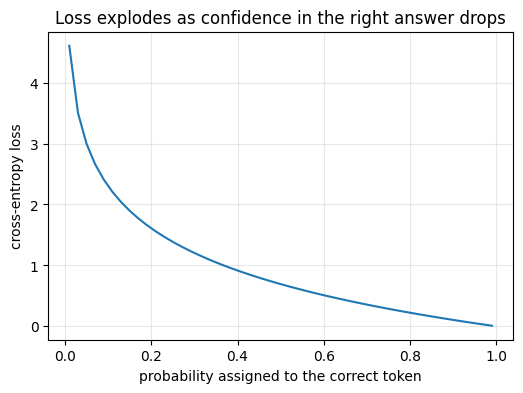

In [11]:
# See how loss changes as the model's confidence in the correct answer changes.
confidences = torch.linspace(0.01, 0.99, 50)
losses = [-torch.log(torch.tensor(p)).item() for p in confidences]

plt.figure(figsize=(6, 4))
plt.plot(confidences, losses)
plt.xlabel("probability assigned to the correct token")
plt.ylabel("cross-entropy loss")
plt.title("Loss explodes as confidence in the right answer drops")
plt.grid(alpha=0.3)
plt.show()


## Exercise
In the last plot, notice loss is near 0 when the model is confident and correct, but grows very fast as confidence in the right answer drops toward 0. This is exactly the loss `GPTMicro.forward()` computes every training step (see `src/model.py` — it calls `F.cross_entropy` on the predicted logits vs. the actual next tokens).

## Summary
- Linear layers transform, activations add nonlinearity, LayerNorm stabilizes scale, residual connections let gradients flow through deep stacks.
- Softmax turns logits into a probability distribution; cross-entropy measures how wrong that distribution is versus the true next token.
- These five ingredients — linear, activation, LayerNorm, residual, softmax+cross-entropy — are *everything* a Transformer block and its training loss are built from. Attention (next) is really the only new idea.

Next: **05 — Attention Mechanism** (the one genuinely new idea that makes Transformers work).
